In [1]:
# Run if needed:
# %pip install pandas numpy matplotlib kagglehub

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import kagglehub
from pathlib import Path

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 15)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", "{:.2f}".format)

print("Pandas version:", pd.__version__)

Pandas version: 3.1.0


## 1. Load dataset from Kaggle

In [2]:
dataset_path = kagglehub.dataset_download(
    "muhammedfakl/livestock-growth-and-weight-prediction-dataset"
)

csv_files = list(Path(dataset_path).rglob("*.csv"))
if not csv_files:
    raise FileNotFoundError("No CSV file found in the downloaded dataset.")

csv_path = csv_files[0]
df = pd.read_csv(csv_path)
print("Dataset file:", csv_path)
print("Dataset loaded successfully!")

Dataset file: /Users/donalsaji/.cache/kagglehub/datasets/muhammedfakl/livestock-growth-and-weight-prediction-dataset/versions/1/livestock_growth_dataset.csv
Dataset loaded successfully!


## 2. Dataset inspection and type handling

In [3]:
display(df.head())
print("Shape (rows, columns):", df.shape)

print("\\nDataFrame information:")
df.info()

print("\\nDescriptive statistics:")
display(df.describe(include="all").T)

print("\\nData types:")
display(df.dtypes)

print("\\nMemory usage (bytes):")
display(df.memory_usage(deep=True))

# Explicit numeric conversion for common cattle measurements
numeric_candidates = [
    "birth_weight_kg", "weight_3m_kg", "weight_12m_kg",
    "withers_height_cm", "chest_girth_cm",
    "colostrum_liters_first_week"
]
for col in numeric_candidates:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Explicit string conversion
for col in ["breed", "sex", "ration_type"]:
    if col in df.columns:
        df[col] = df[col].astype("string")

display(df.dtypes)

,animal_id,breed,sex,birth_weight_kg,withers_height_cm,chest_girth_cm,body_length_cm,colostrum_liters_first_week,early_health_score,ration_type,daily_dry_matter_intake_kg,disease_history_first_3m,weight_3m_kg,weight_6m_kg,weight_12m_kg
0,ANM-00001,Hereford,Female,31.10,74.40,77.10,61.60,24.80,5,high_energy,5.22,0,105.30,205.10,344.30
1,ANM-00002,Jersey,Male,40.80,70.30,78.60,59.70,8.60,4,standard,4.67,0,88.00,177.40,282.60
2,ANM-00003,Limuzin,Female,41.30,77.70,87.90,76.00,25.00,3,high_protein,5.52,1,109.90,188.20,296.60
3,ANM-00004,Angus,Female,33.10,75.80,92.00,85.70,25.00,5,standard,5.44,0,117.40,213.30,336.90
4,ANM-00005,Holstein,Male,39.10,79.10,87.00,73.80,22.20,4,high_energy,6.67,0,129.40,259.20,465.50


Shape (rows, columns): (2000, 15)
\nDataFrame information:
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 15 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   animal_id                    2000 non-null   str    
 1   breed                        2000 non-null   str    
 2   sex                          2000 non-null   str    
 3   birth_weight_kg              2000 non-null   float64
 4   withers_height_cm            2000 non-null   float64
 5   chest_girth_cm               2000 non-null   float64
 6   body_length_cm               2000 non-null   float64
 7   colostrum_liters_first_week  2000 non-null   float64
 8   early_health_score           2000 non-null   int64  
 9   ration_type                  2000 non-null   str    
 10  daily_dry_matter_intake_kg   2000 non-null   float64
 11  disease_history_first_3m     2000 non-null   int64  
 12  weight_3m_kg                

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
animal_id,2000,2000,ANM-00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
breed,2000,6,Holstein,452,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,2000,2,Male,1121,NaN,NaN,NaN,NaN,NaN,NaN,NaN
birth_weight_kg,2000.00,NaN,NaN,NaN,36.25,4.36,25.10,33.30,36.40,39.40,48.00
withers_height_cm,2000.00,NaN,NaN,NaN,74.89,6.26,60.00,70.70,75.20,79.40,92.00
chest_girth_cm,2000.00,NaN,NaN,NaN,83.59,7.44,68.00,78.00,83.80,88.80,102.00
body_length_cm,2000.00,NaN,NaN,NaN,72.92,7.04,58.10,68.00,72.80,77.80,91.70
colostrum_liters_first_week,2000.00,NaN,NaN,NaN,16.89,4.92,8.00,13.07,16.55,20.90,26.00
early_health_score,2000.00,NaN,NaN,NaN,3.65,1.12,1.00,3.00,4.00,5.00,5.00
ration_type,2000,3,standard,1024,NaN,NaN,NaN,NaN,NaN,NaN,NaN


\nData types:


animal_id                          str
breed                              str
sex                                str
birth_weight_kg                float64
withers_height_cm              float64
chest_girth_cm                 float64
body_length_cm                 float64
colostrum_liters_first_week    float64
early_health_score               int64
ration_type                        str
daily_dry_matter_intake_kg     float64
disease_history_first_3m         int64
weight_3m_kg                   float64
weight_6m_kg                   float64
weight_12m_kg                  float64
dtype: object

\nMemory usage (bytes):


Index                           132
animal_id                     34000
breed                         30658
sex                           25758
birth_weight_kg               16000
                              ...  
daily_dry_matter_intake_kg    16000
disease_history_first_3m      16000
weight_3m_kg                  16000
weight_6m_kg                  16000
weight_12m_kg                 16000
Length: 16, dtype: int64

animal_id                          str
breed                           string
sex                             string
birth_weight_kg                float64
withers_height_cm              float64
chest_girth_cm                 float64
body_length_cm                 float64
colostrum_liters_first_week    float64
early_health_score               int64
ration_type                     string
daily_dry_matter_intake_kg     float64
disease_history_first_3m         int64
weight_3m_kg                   float64
weight_6m_kg                   float64
weight_12m_kg                  float64
dtype: object

## 3. Subsetting and filtering

In [4]:
# Position slicing (iloc) and label slicing (loc)
display(df.iloc[:5])
display(df.loc[df.index[:3]])

# Single condition
if "weight_12m_kg" in df.columns:
    display(df[df["weight_12m_kg"] > 100].head())

# Multi-condition: AND, OR, and NOT
if {"weight_12m_kg", "breed"}.issubset(df.columns):
    display(df.loc[(df["weight_12m_kg"] > 100) & df["breed"].notna()].head())
    first_breed = df["breed"].dropna().iloc[0]
    display(df.loc[(df["breed"] == first_breed) | (df["weight_12m_kg"] > 100)].head())
    display(df.loc[~df["breed"].isna()].head())

# query()
if "weight_12m_kg" in df.columns:
    display(df.query("weight_12m_kg >= 100").head())

# Exact column selection and regex filtering
selected = [c for c in ["breed", "sex", "birth_weight_kg", "weight_12m_kg"] if c in df.columns]
display(df[selected].head())
display(df.filter(regex="weight|height|girth").head())

# isin()
if "ration_type" in df.columns:
    choices = df["ration_type"].dropna().unique()[:2]
    display(df[df["ration_type"].isin(choices)].head())

# Extreme values
if "weight_12m_kg" in df.columns:
    display(df.nlargest(5, "weight_12m_kg"))
    display(df.nsmallest(5, "weight_12m_kg"))

,animal_id,breed,sex,birth_weight_kg,withers_height_cm,chest_girth_cm,body_length_cm,colostrum_liters_first_week,early_health_score,ration_type,daily_dry_matter_intake_kg,disease_history_first_3m,weight_3m_kg,weight_6m_kg,weight_12m_kg
0,ANM-00001,Hereford,Female,31.10,74.40,77.10,61.60,24.80,5,high_energy,5.22,0,105.30,205.10,344.30
1,ANM-00002,Jersey,Male,40.80,70.30,78.60,59.70,8.60,4,standard,4.67,0,88.00,177.40,282.60
2,ANM-00003,Limuzin,Female,41.30,77.70,87.90,76.00,25.00,3,high_protein,5.52,1,109.90,188.20,296.60
3,ANM-00004,Angus,Female,33.10,75.80,92.00,85.70,25.00,5,standard,5.44,0,117.40,213.30,336.90
4,ANM-00005,Holstein,Male,39.10,79.10,87.00,73.80,22.20,4,high_energy,6.67,0,129.40,259.20,465.50


,animal_id,breed,sex,birth_weight_kg,withers_height_cm,chest_girth_cm,body_length_cm,colostrum_liters_first_week,early_health_score,ration_type,daily_dry_matter_intake_kg,disease_history_first_3m,weight_3m_kg,weight_6m_kg,weight_12m_kg
0,ANM-00001,Hereford,Female,31.10,74.40,77.10,61.60,24.80,5,high_energy,5.22,0,105.30,205.10,344.30
1,ANM-00002,Jersey,Male,40.80,70.30,78.60,59.70,8.60,4,standard,4.67,0,88.00,177.40,282.60
2,ANM-00003,Limuzin,Female,41.30,77.70,87.90,76.00,25.00,3,high_protein,5.52,1,109.90,188.20,296.60


,animal_id,breed,sex,birth_weight_kg,withers_height_cm,chest_girth_cm,body_length_cm,colostrum_liters_first_week,early_health_score,ration_type,daily_dry_matter_intake_kg,disease_history_first_3m,weight_3m_kg,weight_6m_kg,weight_12m_kg
0,ANM-00001,Hereford,Female,31.10,74.40,77.10,61.60,24.80,5,high_energy,5.22,0,105.30,205.10,344.30
1,ANM-00002,Jersey,Male,40.80,70.30,78.60,59.70,8.60,4,standard,4.67,0,88.00,177.40,282.60
2,ANM-00003,Limuzin,Female,41.30,77.70,87.90,76.00,25.00,3,high_protein,5.52,1,109.90,188.20,296.60
3,ANM-00004,Angus,Female,33.10,75.80,92.00,85.70,25.00,5,standard,5.44,0,117.40,213.30,336.90
4,ANM-00005,Holstein,Male,39.10,79.10,87.00,73.80,22.20,4,high_energy,6.67,0,129.40,259.20,465.50


,animal_id,breed,sex,birth_weight_kg,withers_height_cm,chest_girth_cm,body_length_cm,colostrum_liters_first_week,early_health_score,ration_type,daily_dry_matter_intake_kg,disease_history_first_3m,weight_3m_kg,weight_6m_kg,weight_12m_kg
0,ANM-00001,Hereford,Female,31.10,74.40,77.10,61.60,24.80,5,high_energy,5.22,0,105.30,205.10,344.30
1,ANM-00002,Jersey,Male,40.80,70.30,78.60,59.70,8.60,4,standard,4.67,0,88.00,177.40,282.60
2,ANM-00003,Limuzin,Female,41.30,77.70,87.90,76.00,25.00,3,high_protein,5.52,1,109.90,188.20,296.60
3,ANM-00004,Angus,Female,33.10,75.80,92.00,85.70,25.00,5,standard,5.44,0,117.40,213.30,336.90
4,ANM-00005,Holstein,Male,39.10,79.10,87.00,73.80,22.20,4,high_energy,6.67,0,129.40,259.20,465.50


,animal_id,breed,sex,birth_weight_kg,withers_height_cm,chest_girth_cm,body_length_cm,colostrum_liters_first_week,early_health_score,ration_type,daily_dry_matter_intake_kg,disease_history_first_3m,weight_3m_kg,weight_6m_kg,weight_12m_kg
0,ANM-00001,Hereford,Female,31.10,74.40,77.10,61.60,24.80,5,high_energy,5.22,0,105.30,205.10,344.30
1,ANM-00002,Jersey,Male,40.80,70.30,78.60,59.70,8.60,4,standard,4.67,0,88.00,177.40,282.60
2,ANM-00003,Limuzin,Female,41.30,77.70,87.90,76.00,25.00,3,high_protein,5.52,1,109.90,188.20,296.60
3,ANM-00004,Angus,Female,33.10,75.80,92.00,85.70,25.00,5,standard,5.44,0,117.40,213.30,336.90
4,ANM-00005,Holstein,Male,39.10,79.10,87.00,73.80,22.20,4,high_energy,6.67,0,129.40,259.20,465.50


,animal_id,breed,sex,birth_weight_kg,withers_height_cm,chest_girth_cm,body_length_cm,colostrum_liters_first_week,early_health_score,ration_type,daily_dry_matter_intake_kg,disease_history_first_3m,weight_3m_kg,weight_6m_kg,weight_12m_kg
0,ANM-00001,Hereford,Female,31.10,74.40,77.10,61.60,24.80,5,high_energy,5.22,0,105.30,205.10,344.30
1,ANM-00002,Jersey,Male,40.80,70.30,78.60,59.70,8.60,4,standard,4.67,0,88.00,177.40,282.60
2,ANM-00003,Limuzin,Female,41.30,77.70,87.90,76.00,25.00,3,high_protein,5.52,1,109.90,188.20,296.60
3,ANM-00004,Angus,Female,33.10,75.80,92.00,85.70,25.00,5,standard,5.44,0,117.40,213.30,336.90
4,ANM-00005,Holstein,Male,39.10,79.10,87.00,73.80,22.20,4,high_energy,6.67,0,129.40,259.20,465.50


... (2 outputs left out)

,birth_weight_kg,withers_height_cm,chest_girth_cm,weight_3m_kg,weight_6m_kg,weight_12m_kg
0,31.10,74.40,77.10,105.30,205.10,344.30
1,40.80,70.30,78.60,88.00,177.40,282.60
2,41.30,77.70,87.90,109.90,188.20,296.60
3,33.10,75.80,92.00,117.40,213.30,336.90
4,39.10,79.10,87.00,129.40,259.20,465.50


,animal_id,breed,sex,birth_weight_kg,withers_height_cm,chest_girth_cm,body_length_cm,colostrum_liters_first_week,early_health_score,ration_type,daily_dry_matter_intake_kg,disease_history_first_3m,weight_3m_kg,weight_6m_kg,weight_12m_kg
0,ANM-00001,Hereford,Female,31.10,74.40,77.10,61.60,24.80,5,high_energy,5.22,0,105.30,205.10,344.30
1,ANM-00002,Jersey,Male,40.80,70.30,78.60,59.70,8.60,4,standard,4.67,0,88.00,177.40,282.60
3,ANM-00004,Angus,Female,33.10,75.80,92.00,85.70,25.00,5,standard,5.44,0,117.40,213.30,336.90
4,ANM-00005,Holstein,Male,39.10,79.10,87.00,73.80,22.20,4,high_energy,6.67,0,129.40,259.20,465.50
5,ANM-00006,Limuzin,Female,36.10,78.00,81.30,78.70,19.80,1,standard,4.28,1,87.20,153.80,238.60


,animal_id,breed,sex,birth_weight_kg,withers_height_cm,chest_girth_cm,body_length_cm,colostrum_liters_first_week,early_health_score,ration_type,daily_dry_matter_intake_kg,disease_history_first_3m,weight_3m_kg,weight_6m_kg,weight_12m_kg
938,ANM-00939,Limuzin,Male,43.80,84.90,92.60,84.10,15.50,5,high_energy,5.48,0,150.10,288.80,477.90
15,ANM-00016,Simmental,Male,39.40,78.60,92.70,80.90,24.40,5,high_energy,5.07,0,139.90,262.60,475.10
136,ANM-00137,Limuzin,Male,41.80,80.30,85.60,73.40,15.80,5,high_energy,6.05,0,141.20,280.70,471.20
4,ANM-00005,Holstein,Male,39.10,79.10,87.00,73.80,22.20,4,high_energy,6.67,0,129.40,259.20,465.50
239,ANM-00240,Holstein,Male,41.10,82.10,90.30,78.50,19.30,5,high_energy,5.88,0,129.50,272.00,463.90


,animal_id,breed,sex,birth_weight_kg,withers_height_cm,chest_girth_cm,body_length_cm,colostrum_liters_first_week,early_health_score,ration_type,daily_dry_matter_intake_kg,disease_history_first_3m,weight_3m_kg,weight_6m_kg,weight_12m_kg
20,ANM-00021,Hereford,Female,38.00,74.10,88.30,70.40,9.70,4,standard,3.20,1,78.70,120.00,220.00
28,ANM-00029,Holstein,Male,32.50,68.80,75.80,65.80,13.30,4,standard,3.99,1,72.50,121.90,220.00
35,ANM-00036,Holstein,Female,36.10,61.70,69.60,63.70,14.00,3,standard,3.06,0,80.40,133.60,220.00
92,ANM-00093,Jersey,Female,36.90,65.80,77.20,67.80,14.10,4,high_protein,3.88,1,66.50,120.00,220.00
118,ANM-00119,Jersey,Male,30.70,71.10,75.20,60.90,9.10,1,standard,2.62,0,65.00,131.70,220.00


## 4. Data cleaning and reshaping

In [5]:
# Missing-value detection
display(df.isnull().sum())

# dropna()
if "weight_12m_kg" in df.columns:
    complete = df.dropna(subset=["weight_12m_kg"])
else:
    complete = df.dropna()
print("Rows after dropna:", len(complete))

# fillna() with numeric medians
filled = df.copy()
for col in filled.select_dtypes(include="number").columns:
    filled[col] = filled[col].fillna(filled[col].median())

# Forward fill and backward fill on a small sample
display(df.head(10).ffill().bfill())

# Remove duplicates
df_clean = df.drop_duplicates().copy()
print("Before:", len(df), "| After:", len(df_clean))

# Sort values and index
if "weight_12m_kg" in df_clean.columns:
    display(df_clean.sort_values("weight_12m_kg", ascending=False).head())
display(df_clean.sort_index().head())

# Method chaining: filter -> select -> sort -> top 10
if {"breed", "weight_12m_kg"}.issubset(df_clean.columns):
    chained = (
        df_clean.loc[df_clean["weight_12m_kg"].notna()]
        .filter(items=["breed", "weight_12m_kg"])
        .sort_values("weight_12m_kg", ascending=False)
        .head(10)
    )
    display(chained)

# Melt (unpivot) weight columns into long format
weight_cols = [c for c in ["birth_weight_kg", "weight_3m_kg", "weight_12m_kg"] if c in df_clean.columns]
if weight_cols:
    ids = [c for c in ["animal_id", "cattle_id", "id", "breed", "sex"] if c in df_clean.columns and c not in weight_cols]
    melted = pd.melt(df_clean, id_vars=ids, value_vars=weight_cols,
                     var_name="growth_stage", value_name="weight_kg")
    display(melted.head())

# Transpose sample
display(df_clean.head(5).T)

animal_id                      0
breed                          0
sex                            0
birth_weight_kg                0
withers_height_cm              0
chest_girth_cm                 0
body_length_cm                 0
colostrum_liters_first_week    0
early_health_score             0
ration_type                    0
daily_dry_matter_intake_kg     0
disease_history_first_3m       0
weight_3m_kg                   0
weight_6m_kg                   0
weight_12m_kg                  0
dtype: int64

Rows after dropna: 2000


,animal_id,breed,sex,birth_weight_kg,withers_height_cm,chest_girth_cm,body_length_cm,colostrum_liters_first_week,early_health_score,ration_type,daily_dry_matter_intake_kg,disease_history_first_3m,weight_3m_kg,weight_6m_kg,weight_12m_kg
0,ANM-00001,Hereford,Female,31.10,74.40,77.10,61.60,24.80,5,high_energy,5.22,0,105.30,205.10,344.30
1,ANM-00002,Jersey,Male,40.80,70.30,78.60,59.70,8.60,4,standard,4.67,0,88.00,177.40,282.60
2,ANM-00003,Limuzin,Female,41.30,77.70,87.90,76.00,25.00,3,high_protein,5.52,1,109.90,188.20,296.60
3,ANM-00004,Angus,Female,33.10,75.80,92.00,85.70,25.00,5,standard,5.44,0,117.40,213.30,336.90
4,ANM-00005,Holstein,Male,39.10,79.10,87.00,73.80,22.20,4,high_energy,6.67,0,129.40,259.20,465.50
5,ANM-00006,Limuzin,Female,36.10,78.00,81.30,78.70,19.80,1,standard,4.28,1,87.20,153.80,238.60
6,ANM-00007,Hereford,Male,38.50,77.10,85.30,74.70,12.90,3,standard,6.33,0,113.10,199.80,360.10
7,ANM-00008,Hereford,Male,31.90,67.00,71.30,65.30,18.40,1,standard,3.61,1,82.70,150.90,224.80
8,ANM-00009,Holstein,Male,36.60,75.80,74.50,64.60,19.50,1,standard,2.75,0,77.40,152.00,267.00
9,ANM-00010,Jersey,Female,32.50,71.60,81.30,63.20,10.50,4,high_energy,3.01,0,65.00,137.10,265.10


Before: 2000 | After: 2000


,animal_id,breed,sex,birth_weight_kg,withers_height_cm,chest_girth_cm,body_length_cm,colostrum_liters_first_week,early_health_score,ration_type,daily_dry_matter_intake_kg,disease_history_first_3m,weight_3m_kg,weight_6m_kg,weight_12m_kg
938,ANM-00939,Limuzin,Male,43.80,84.90,92.60,84.10,15.50,5,high_energy,5.48,0,150.10,288.80,477.90
15,ANM-00016,Simmental,Male,39.40,78.60,92.70,80.90,24.40,5,high_energy,5.07,0,139.90,262.60,475.10
136,ANM-00137,Limuzin,Male,41.80,80.30,85.60,73.40,15.80,5,high_energy,6.05,0,141.20,280.70,471.20
4,ANM-00005,Holstein,Male,39.10,79.10,87.00,73.80,22.20,4,high_energy,6.67,0,129.40,259.20,465.50
239,ANM-00240,Holstein,Male,41.10,82.10,90.30,78.50,19.30,5,high_energy,5.88,0,129.50,272.00,463.90


,animal_id,breed,sex,birth_weight_kg,withers_height_cm,chest_girth_cm,body_length_cm,colostrum_liters_first_week,early_health_score,ration_type,daily_dry_matter_intake_kg,disease_history_first_3m,weight_3m_kg,weight_6m_kg,weight_12m_kg
0,ANM-00001,Hereford,Female,31.10,74.40,77.10,61.60,24.80,5,high_energy,5.22,0,105.30,205.10,344.30
1,ANM-00002,Jersey,Male,40.80,70.30,78.60,59.70,8.60,4,standard,4.67,0,88.00,177.40,282.60
2,ANM-00003,Limuzin,Female,41.30,77.70,87.90,76.00,25.00,3,high_protein,5.52,1,109.90,188.20,296.60
3,ANM-00004,Angus,Female,33.10,75.80,92.00,85.70,25.00,5,standard,5.44,0,117.40,213.30,336.90
4,ANM-00005,Holstein,Male,39.10,79.10,87.00,73.80,22.20,4,high_energy,6.67,0,129.40,259.20,465.50


,breed,weight_12m_kg
938,Limuzin,477.90
15,Simmental,475.10
136,Limuzin,471.20
4,Holstein,465.50
239,Holstein,463.90
1646,Simmental,461.90
1683,Simmental,460.80
1024,Angus,459.20
1353,Simmental,456.70
415,Simmental,455.30


,animal_id,breed,sex,growth_stage,weight_kg
0,ANM-00001,Hereford,Female,birth_weight_kg,31.10
1,ANM-00002,Jersey,Male,birth_weight_kg,40.80
2,ANM-00003,Limuzin,Female,birth_weight_kg,41.30
3,ANM-00004,Angus,Female,birth_weight_kg,33.10
4,ANM-00005,Holstein,Male,birth_weight_kg,39.10


,0,1,2,3,4
animal_id,ANM-00001,ANM-00002,ANM-00003,ANM-00004,ANM-00005
breed,Hereford,Jersey,Limuzin,Angus,Holstein
sex,Female,Male,Female,Female,Male
birth_weight_kg,31.10,40.80,41.30,33.10,39.10
withers_height_cm,74.40,70.30,77.70,75.80,79.10
chest_girth_cm,77.10,78.60,87.90,92.00,87.00
body_length_cm,61.60,59.70,76.00,85.70,73.80
colostrum_liters_first_week,24.80,8.60,25.00,25.00,22.20
early_health_score,5,4,3,5,4
ration_type,high_energy,standard,high_protein,standard,high_energy


## 5. Column engineering and group aggregation

In [6]:
engineered = df_clean.copy()

# assign() and vectorized arithmetic
if {"weight_12m_kg", "birth_weight_kg"}.issubset(engineered.columns):
    engineered = engineered.assign(
        weight_gain_12m_kg=engineered["weight_12m_kg"] - engineered["birth_weight_kg"]
    )

# Binning with pd.cut()
if "weight_12m_kg" in engineered.columns:
    engineered["weight_category"] = pd.cut(
        engineered["weight_12m_kg"],
        bins=[0, 100, 200, 300, np.inf],
        labels=["Low", "Medium", "High", "Very High"],
        right=False
    )
    display(engineered[["weight_12m_kg", "weight_category"]].head())

# groupby() and multiple aggregations
if {"breed", "weight_12m_kg"}.issubset(engineered.columns):
    summary = engineered.groupby("breed").agg(
        cattle_count=("weight_12m_kg", "count"),
        average_weight=("weight_12m_kg", "mean"),
        total_weight=("weight_12m_kg", "sum"),
        weight_std=("weight_12m_kg", "std")
    ).sort_values("average_weight", ascending=False)
    display(summary)
    display(engineered.groupby("breed").size().rename("records_per_breed"))

# Cumulative and rolling/window calculations
if "weight_12m_kg" in engineered.columns:
    engineered["cumulative_weight"] = engineered["weight_12m_kg"].fillna(0).cumsum()
    engineered["running_max_weight"] = engineered["weight_12m_kg"].cummax()
    engineered["rolling_avg_weight"] = engineered["weight_12m_kg"].rolling(5, min_periods=1).mean()
    display(engineered[["weight_12m_kg", "cumulative_weight",
                        "running_max_weight", "rolling_avg_weight"]].head(10))

,weight_12m_kg,weight_category
0,344.30,Very High
1,282.60,High
2,296.60,High
3,336.90,Very High
4,465.50,Very High


,cattle_count,average_weight,total_weight,weight_std
breed,,,,
Limuzin,335,347.46,116400.00,51.15
Simmental,384,341.60,131174.90,50.36
Hereford,283,319.59,90444.10,50.68
Holstein,452,310.92,140535.50,52.14
Angus,299,310.68,92893.70,52.63
Jersey,247,255.88,63202.90,36.49


breed
Angus        299
Hereford     283
Holstein     452
Jersey       247
Limuzin      335
Simmental    384
Name: records_per_breed, dtype: int64

,weight_12m_kg,cumulative_weight,running_max_weight,rolling_avg_weight
0,344.30,344.30,344.30,344.30
1,282.60,626.90,344.30,313.45
2,296.60,923.50,344.30,307.83
3,336.90,1260.40,344.30,315.10
4,465.50,1725.90,465.50,345.18
5,238.60,1964.50,465.50,324.04
6,360.10,2324.60,465.50,339.54
7,224.80,2549.40,465.50,325.18
8,267.00,2816.40,465.50,311.20
9,265.10,3081.50,465.50,271.12


## 6. Vectorized string and datetime operations

In [7]:
# Vectorized string operations
if "breed" in df_clean.columns:
    strings = df_clean[["breed"]].copy()
    strings["breed_title"] = strings["breed"].astype("string").str.title()
    strings["breed_length"] = strings["breed"].astype("string").str.len()
    strings["breed_clean"] = strings["breed"].astype("string").str.replace(r"[^A-Za-z ]", "", regex=True)
    strings["breed_first_word"] = strings["breed_clean"].str.split().str[0]
    display(strings.head())

# Datetime parsing and .dt accessors
date_candidates = ["birth_date", "date", "record_date", "collection_date"]
date_col = next((c for c in date_candidates if c in df_clean.columns), None)

if date_col:
    dates = df_clean[[date_col]].copy()
    dates[date_col] = pd.to_datetime(dates[date_col], errors="coerce")
    dates["year"] = dates[date_col].dt.year
    dates["month"] = dates[date_col].dt.month
    dates["day"] = dates[date_col].dt.day
    dates["quarter"] = dates[date_col].dt.quarter
    display(dates.head())
else:
    print("No date field found; demonstrating .dt with sample dates.")
    example_dates = pd.Series(pd.to_datetime(["2025-01-15", "2025-04-20", "2025-10-05"]))
    display(pd.DataFrame({
        "date": example_dates, "year": example_dates.dt.year,
        "month": example_dates.dt.month, "day": example_dates.dt.day,
        "quarter": example_dates.dt.quarter
    }))

,breed,breed_title,breed_length,breed_clean,breed_first_word
0,Hereford,Hereford,8,Hereford,Hereford
1,Jersey,Jersey,6,Jersey,Jersey
2,Limuzin,Limuzin,7,Limuzin,Limuzin
3,Angus,Angus,5,Angus,Angus
4,Holstein,Holstein,8,Holstein,Holstein


No date field found; demonstrating .dt with sample dates.


,date,year,month,day,quarter
0,2025-01-15,2025,1,15,1
1,2025-04-20,2025,4,20,2
2,2025-10-05,2025,10,5,4


## 7. Merging and combining data

In [8]:
# Create a breed lookup table and demonstrate joins
if "breed" in df_clean.columns:
    breed_lookup = pd.DataFrame({
        "breed": sorted(df_clean["breed"].dropna().unique()),
        "breed_group": ["Known breed"] * df_clean["breed"].dropna().nunique()
    })

    # Inner, left, right, and outer joins
    display(pd.merge(df_clean, breed_lookup, on="breed", how="inner").head())
    display(pd.merge(df_clean.head(5), breed_lookup, on="breed", how="left").head())
    display(pd.merge(df_clean.head(5), breed_lookup, on="breed", how="right").head())
    display(pd.merge(df_clean.head(5), breed_lookup, on="breed", how="outer").head())

# concat() combines two row subsets
combined = pd.concat([df_clean.head(5), df_clean.tail(5)], axis=0)
display(combined)

,animal_id,breed,sex,birth_weight_kg,withers_height_cm,chest_girth_cm,body_length_cm,colostrum_liters_first_week,early_health_score,ration_type,daily_dry_matter_intake_kg,disease_history_first_3m,weight_3m_kg,weight_6m_kg,weight_12m_kg,breed_group
0,ANM-00001,Hereford,Female,31.10,74.40,77.10,61.60,24.80,5,high_energy,5.22,0,105.30,205.10,344.30,Known breed
1,ANM-00002,Jersey,Male,40.80,70.30,78.60,59.70,8.60,4,standard,4.67,0,88.00,177.40,282.60,Known breed
2,ANM-00003,Limuzin,Female,41.30,77.70,87.90,76.00,25.00,3,high_protein,5.52,1,109.90,188.20,296.60,Known breed
3,ANM-00004,Angus,Female,33.10,75.80,92.00,85.70,25.00,5,standard,5.44,0,117.40,213.30,336.90,Known breed
4,ANM-00005,Holstein,Male,39.10,79.10,87.00,73.80,22.20,4,high_energy,6.67,0,129.40,259.20,465.50,Known breed


,animal_id,breed,sex,birth_weight_kg,withers_height_cm,chest_girth_cm,body_length_cm,colostrum_liters_first_week,early_health_score,ration_type,daily_dry_matter_intake_kg,disease_history_first_3m,weight_3m_kg,weight_6m_kg,weight_12m_kg,breed_group
0,ANM-00001,Hereford,Female,31.10,74.40,77.10,61.60,24.80,5,high_energy,5.22,0,105.30,205.10,344.30,Known breed
1,ANM-00002,Jersey,Male,40.80,70.30,78.60,59.70,8.60,4,standard,4.67,0,88.00,177.40,282.60,Known breed
2,ANM-00003,Limuzin,Female,41.30,77.70,87.90,76.00,25.00,3,high_protein,5.52,1,109.90,188.20,296.60,Known breed
3,ANM-00004,Angus,Female,33.10,75.80,92.00,85.70,25.00,5,standard,5.44,0,117.40,213.30,336.90,Known breed
4,ANM-00005,Holstein,Male,39.10,79.10,87.00,73.80,22.20,4,high_energy,6.67,0,129.40,259.20,465.50,Known breed


,animal_id,breed,sex,birth_weight_kg,withers_height_cm,chest_girth_cm,body_length_cm,colostrum_liters_first_week,early_health_score,ration_type,daily_dry_matter_intake_kg,disease_history_first_3m,weight_3m_kg,weight_6m_kg,weight_12m_kg,breed_group
0,ANM-00004,Angus,Female,33.10,75.80,92.00,85.70,25.00,5.00,standard,5.44,0.00,117.40,213.30,336.90,Known breed
1,ANM-00001,Hereford,Female,31.10,74.40,77.10,61.60,24.80,5.00,high_energy,5.22,0.00,105.30,205.10,344.30,Known breed
2,ANM-00005,Holstein,Male,39.10,79.10,87.00,73.80,22.20,4.00,high_energy,6.67,0.00,129.40,259.20,465.50,Known breed
3,ANM-00002,Jersey,Male,40.80,70.30,78.60,59.70,8.60,4.00,standard,4.67,0.00,88.00,177.40,282.60,Known breed
4,ANM-00003,Limuzin,Female,41.30,77.70,87.90,76.00,25.00,3.00,high_protein,5.52,1.00,109.90,188.20,296.60,Known breed


,animal_id,breed,sex,birth_weight_kg,withers_height_cm,chest_girth_cm,body_length_cm,colostrum_liters_first_week,early_health_score,ration_type,daily_dry_matter_intake_kg,disease_history_first_3m,weight_3m_kg,weight_6m_kg,weight_12m_kg,breed_group
0,ANM-00004,Angus,Female,33.10,75.80,92.00,85.70,25.00,5.00,standard,5.44,0.00,117.40,213.30,336.90,Known breed
1,ANM-00001,Hereford,Female,31.10,74.40,77.10,61.60,24.80,5.00,high_energy,5.22,0.00,105.30,205.10,344.30,Known breed
2,ANM-00005,Holstein,Male,39.10,79.10,87.00,73.80,22.20,4.00,high_energy,6.67,0.00,129.40,259.20,465.50,Known breed
3,ANM-00002,Jersey,Male,40.80,70.30,78.60,59.70,8.60,4.00,standard,4.67,0.00,88.00,177.40,282.60,Known breed
4,ANM-00003,Limuzin,Female,41.30,77.70,87.90,76.00,25.00,3.00,high_protein,5.52,1.00,109.90,188.20,296.60,Known breed


,animal_id,breed,sex,birth_weight_kg,withers_height_cm,chest_girth_cm,body_length_cm,colostrum_liters_first_week,early_health_score,ration_type,daily_dry_matter_intake_kg,disease_history_first_3m,weight_3m_kg,weight_6m_kg,weight_12m_kg
0,ANM-00001,Hereford,Female,31.10,74.40,77.10,61.60,24.80,5,high_energy,5.22,0,105.30,205.10,344.30
1,ANM-00002,Jersey,Male,40.80,70.30,78.60,59.70,8.60,4,standard,4.67,0,88.00,177.40,282.60
2,ANM-00003,Limuzin,Female,41.30,77.70,87.90,76.00,25.00,3,high_protein,5.52,1,109.90,188.20,296.60
3,ANM-00004,Angus,Female,33.10,75.80,92.00,85.70,25.00,5,standard,5.44,0,117.40,213.30,336.90
4,ANM-00005,Holstein,Male,39.10,79.10,87.00,73.80,22.20,4,high_energy,6.67,0,129.40,259.20,465.50
1995,ANM-01996,Hereford,Male,37.50,76.80,81.00,67.30,24.50,3,standard,5.46,0,111.10,208.60,357.70
1996,ANM-01997,Simmental,Male,37.60,74.30,81.10,81.30,22.50,5,high_energy,4.58,1,109.70,208.30,353.80
1997,ANM-01998,Simmental,Male,34.40,68.80,80.90,74.20,19.90,3,high_protein,6.97,0,121.90,223.00,358.30
1998,ANM-01999,Limuzin,Male,41.90,82.60,83.70,65.80,17.50,5,high_protein,4.20,0,129.70,240.20,396.20
1999,ANM-02000,Jersey,Male,27.80,71.80,69.40,63.60,24.60,4,high_protein,3.68,0,80.80,153.00,273.10


## 8. Visualization using native Pandas plots

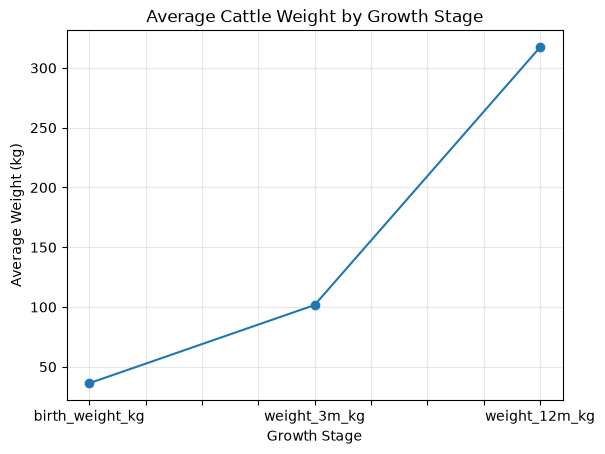

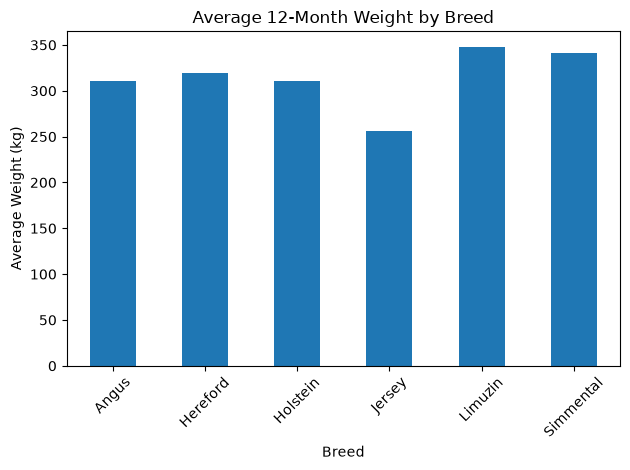

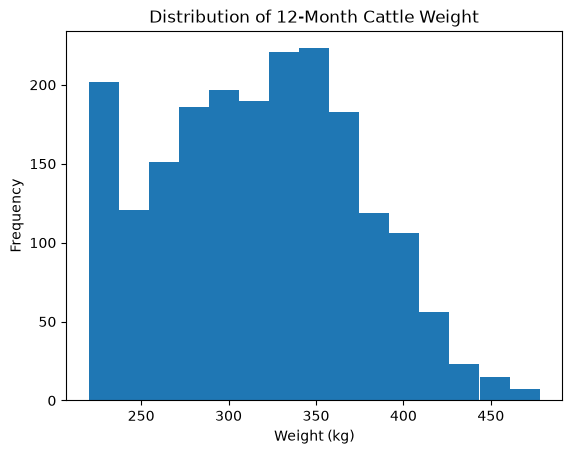

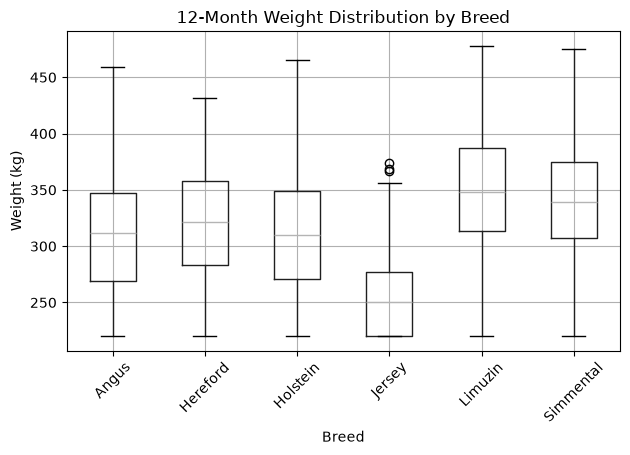

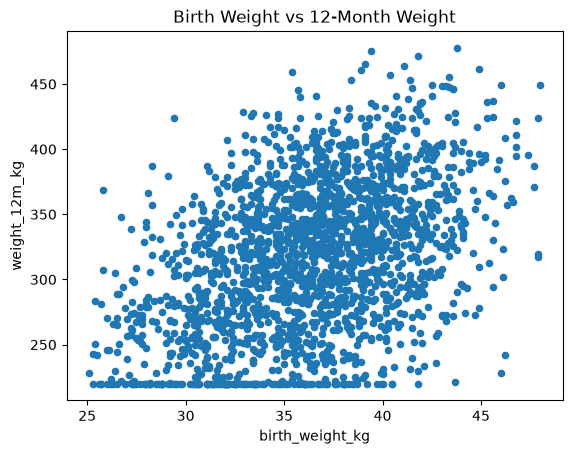

In [9]:
# Line plot: mean weights across growth stages
weight_cols = [c for c in ["birth_weight_kg", "weight_3m_kg", "weight_12m_kg"] if c in df_clean.columns]
if weight_cols:
    df_clean[weight_cols].mean().plot(kind="line", marker="o", title="Average Cattle Weight by Growth Stage")
    plt.xlabel("Growth Stage")
    plt.ylabel("Average Weight (kg)")
    plt.grid(True, alpha=0.3)
    plt.show()

# Bar chart: average 12-month weight by breed
if {"breed", "weight_12m_kg"}.issubset(df_clean.columns):
    df_clean.groupby("breed")["weight_12m_kg"].mean().plot(kind="bar", title="Average 12-Month Weight by Breed")
    plt.xlabel("Breed")
    plt.ylabel("Average Weight (kg)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# Histogram
if "weight_12m_kg" in df_clean.columns:
    df_clean["weight_12m_kg"].plot(kind="hist", bins=15, title="Distribution of 12-Month Cattle Weight")
    plt.xlabel("Weight (kg)")
    plt.show()

# Boxplot
if {"breed", "weight_12m_kg"}.issubset(df_clean.columns):
    df_clean.boxplot(column="weight_12m_kg", by="breed", rot=45)
    plt.title("12-Month Weight Distribution by Breed")
    plt.suptitle("")
    plt.xlabel("Breed")
    plt.ylabel("Weight (kg)")
    plt.tight_layout()
    plt.show()

# Scatter plot
if {"birth_weight_kg", "weight_12m_kg"}.issubset(df_clean.columns):
    df_clean.plot(kind="scatter", x="birth_weight_kg", y="weight_12m_kg",
                  title="Birth Weight vs 12-Month Weight")
    plt.show()